## Oresund

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

FileNotFoundError: [Errno 2] No such file or directory: 'datasets/observations/stations.csv'

## Load Data and Measurement

In [3]:
# OPEN FOLDERS
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"
msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

ds = dfs.read(time = slice("2019-01-01", "2023-10-31"))

# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
#hf = ["Drogden", "Klagshamn", "Dragor", "Barseback"]
# availabilities 97-50-98-50
#alllist = [s for s in alllist if s.name in hf]

# Extract the values and convert to torch tensors

measurements = extract_water_level_measurements(alllist, ds_time=ds.time, obs_fldr=obs_fldr)
measurements = torch.as_tensor(measurements, dtype=torch.float32)
print("IN:\nMeasurements shape:", measurements.shape)

# Build a single mask for nodes that are valid in all output fields
surface = ds["Surface elevation"].values
u_velocity = ds["U velocity"].values
v_velocity = ds["V velocity"].values
valid_nodes = np.isfinite(surface).all(axis=0) & np.isfinite(u_velocity).all(axis=0) & np.isfinite(v_velocity).all(axis=0)

# outputs
H = torch.from_numpy(surface[:, valid_nodes].astype(np.float32, copy=False))
U = torch.from_numpy(u_velocity[:, valid_nodes].astype(np.float32, copy=False))
V = torch.from_numpy(v_velocity[:, valid_nodes].astype(np.float32, copy=False))

# print the shape of the arrays
print("OUT:\nH shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)

# free memory
del surface, u_velocity, v_velocity, valid_nodes, dfs

IN:
Measurements shape: torch.Size([84720, 12])
OUT:
H shape: torch.Size([84720, 3320])
U shape: torch.Size([84720, 3320])
V shape: torch.Size([84720, 3320])


In [4]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.70        # percentage of data used for training 
VAL_SIZE = 0.15          # percentage of data used for validation
TEST_SIZE = 0.15         # percentage of data used for testing

COMPRESS_H = 15         # modes kept for H (surface elevation)
COMPRESS_U = 100         # modes kept for U (U velocity)
COMPRESS_V = 100         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 3               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64,96]     # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.1.A): Median imputer

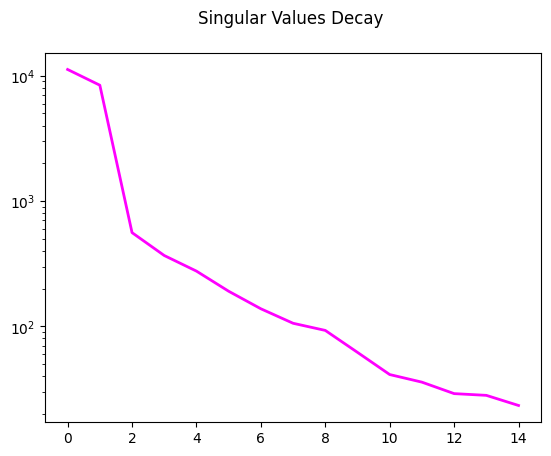

Residual energy of Surface elevation after keeping 15 modes: 0.0015 %


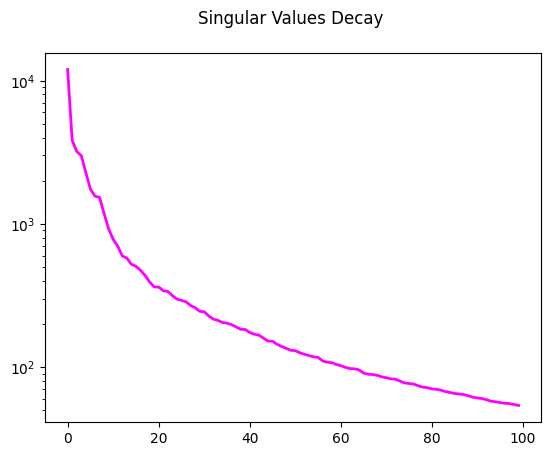

Residual energy of U velocity after keeping 100 modes: 0.0711 %


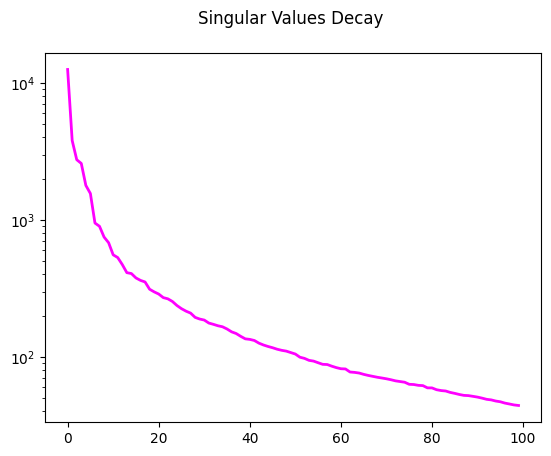

Residual energy of V velocity after keeping 100 modes: 0.0514 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 12]) -> torch.Size([59303, 215])
Val:	 torch.Size([12709, 24, 12]) -> torch.Size([12709, 215])
Test:	 torch.Size([12708, 24, 12]) -> torch.Size([12708, 215])

Input shape for the model: 12
Output shape for the model: 215


In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="median", verbose=True)
manager.add_data(U, id="U velocity", compress=COMPRESS_U, verbose=True)
manager.add_data(V, id="V velocity", compress=COMPRESS_V, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training:  66%|██████▋   | 133/200 [36:13<18:15, 16.34s/it, Train Loss=0.00345, Val Loss=0.00375, Patience=39, Best Val Loss=0.00374, LR=1.23e-04]

Early stopping at epoch 134
Training completed with best validation loss: 0.0037


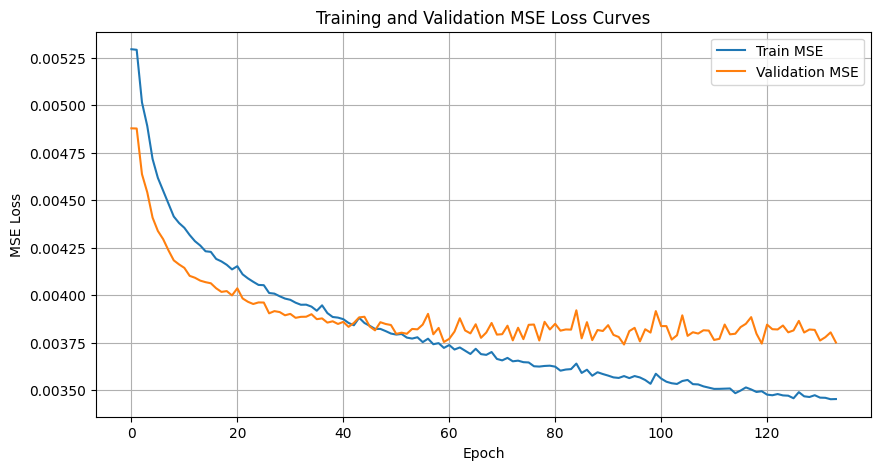

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.00374,0.004024,0.133716,0.137047,0.138871


In [6]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.A): median imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.1.A)_median_imputation.png


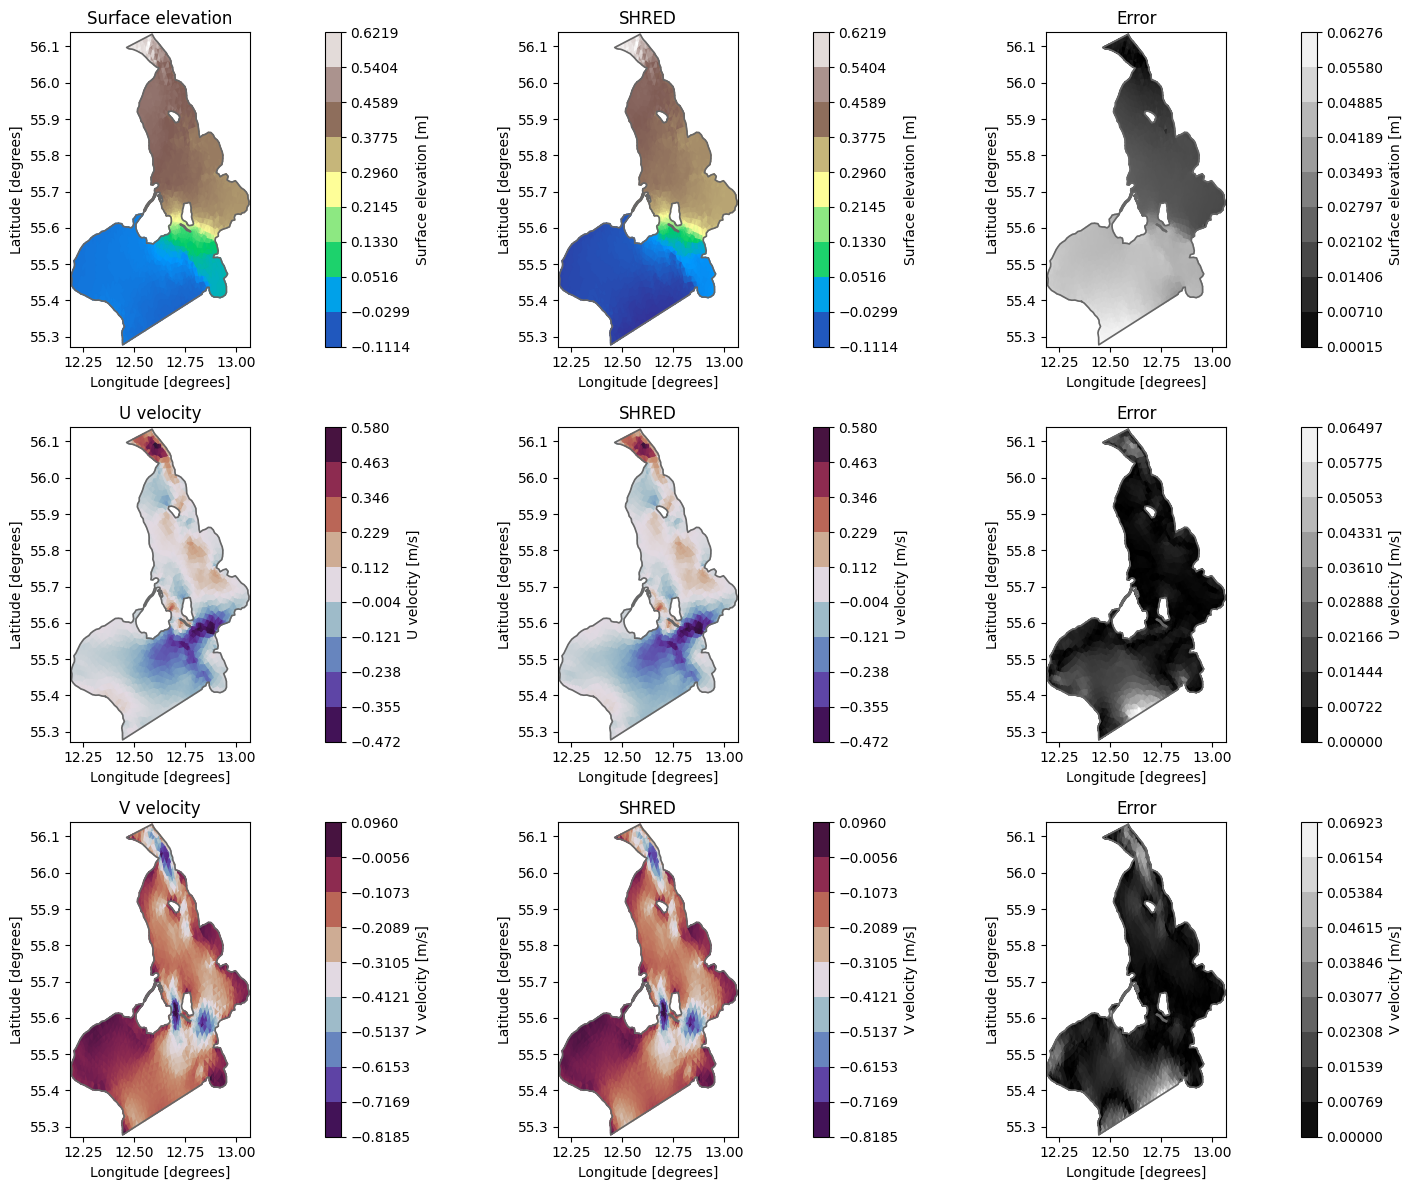

In [7]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.A)_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.B): Mean imputer

In [8]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="mean")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 215])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 215])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 215])

Input shape for the model: 13
Output shape for the model: 215


Starting training...


Training:  96%|█████████▌| 191/200 [51:48<02:26, 16.28s/it, Train Loss=0.00340, Val Loss=0.00375, Patience=39, Best Val Loss=0.00373, LR=1.97e-06]

Early stopping at epoch 192
Training completed with best validation loss: 0.0037


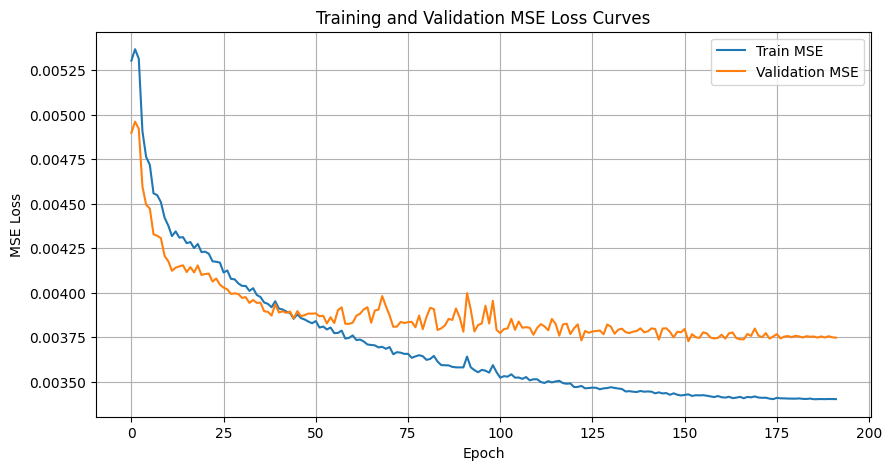

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968


In [9]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.B): mean imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.1.B)_mean_imputation.png


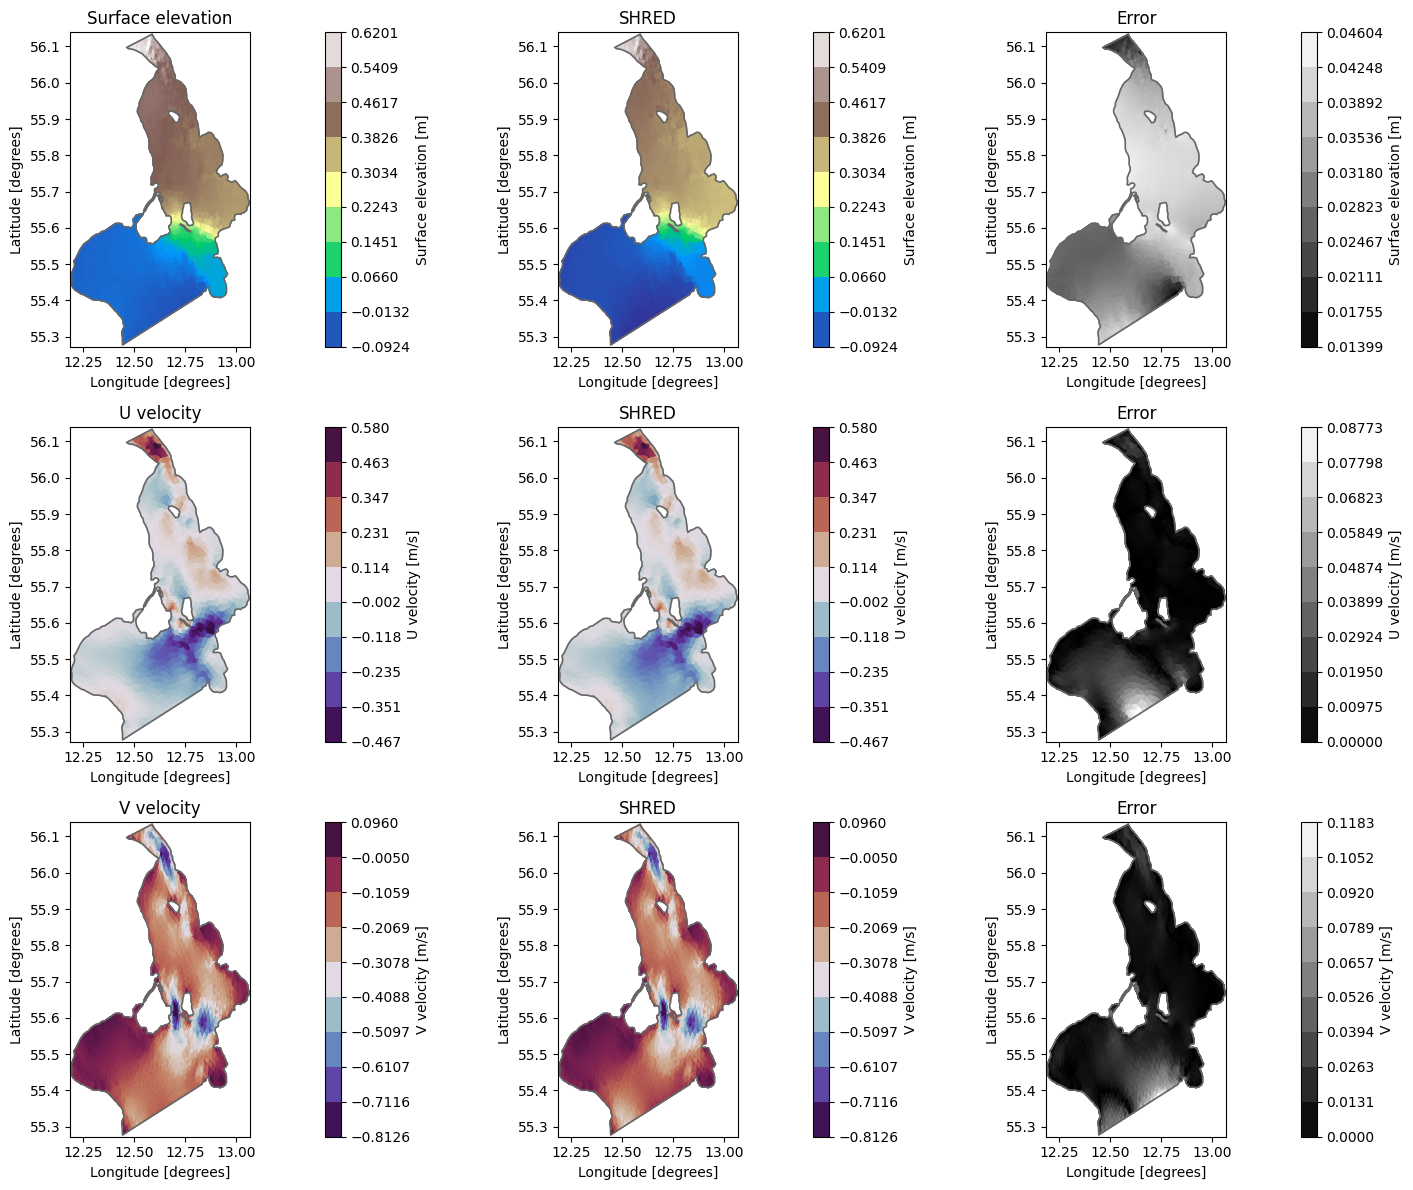

In [10]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.B)_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.C): Last value imputer

In [11]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="last_value")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 215])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 215])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 215])

Input shape for the model: 13
Output shape for the model: 215


Starting training...


Training:  70%|███████   | 140/200 [38:55<16:41, 16.69s/it, Train Loss=0.00322, Val Loss=0.00375, Patience=39, Best Val Loss=0.00369, LR=9.99e-05]

Early stopping at epoch 141
Training completed with best validation loss: 0.0037


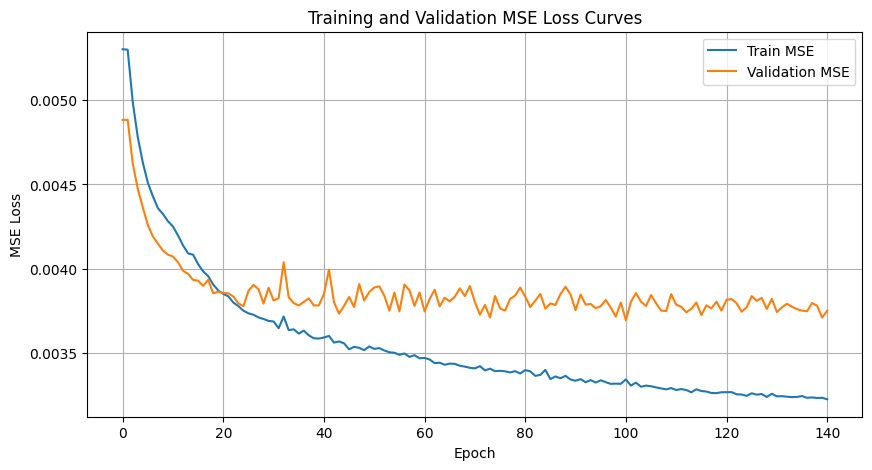

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002


In [12]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.C): last-value imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.1.C)_last_value_imputation.png


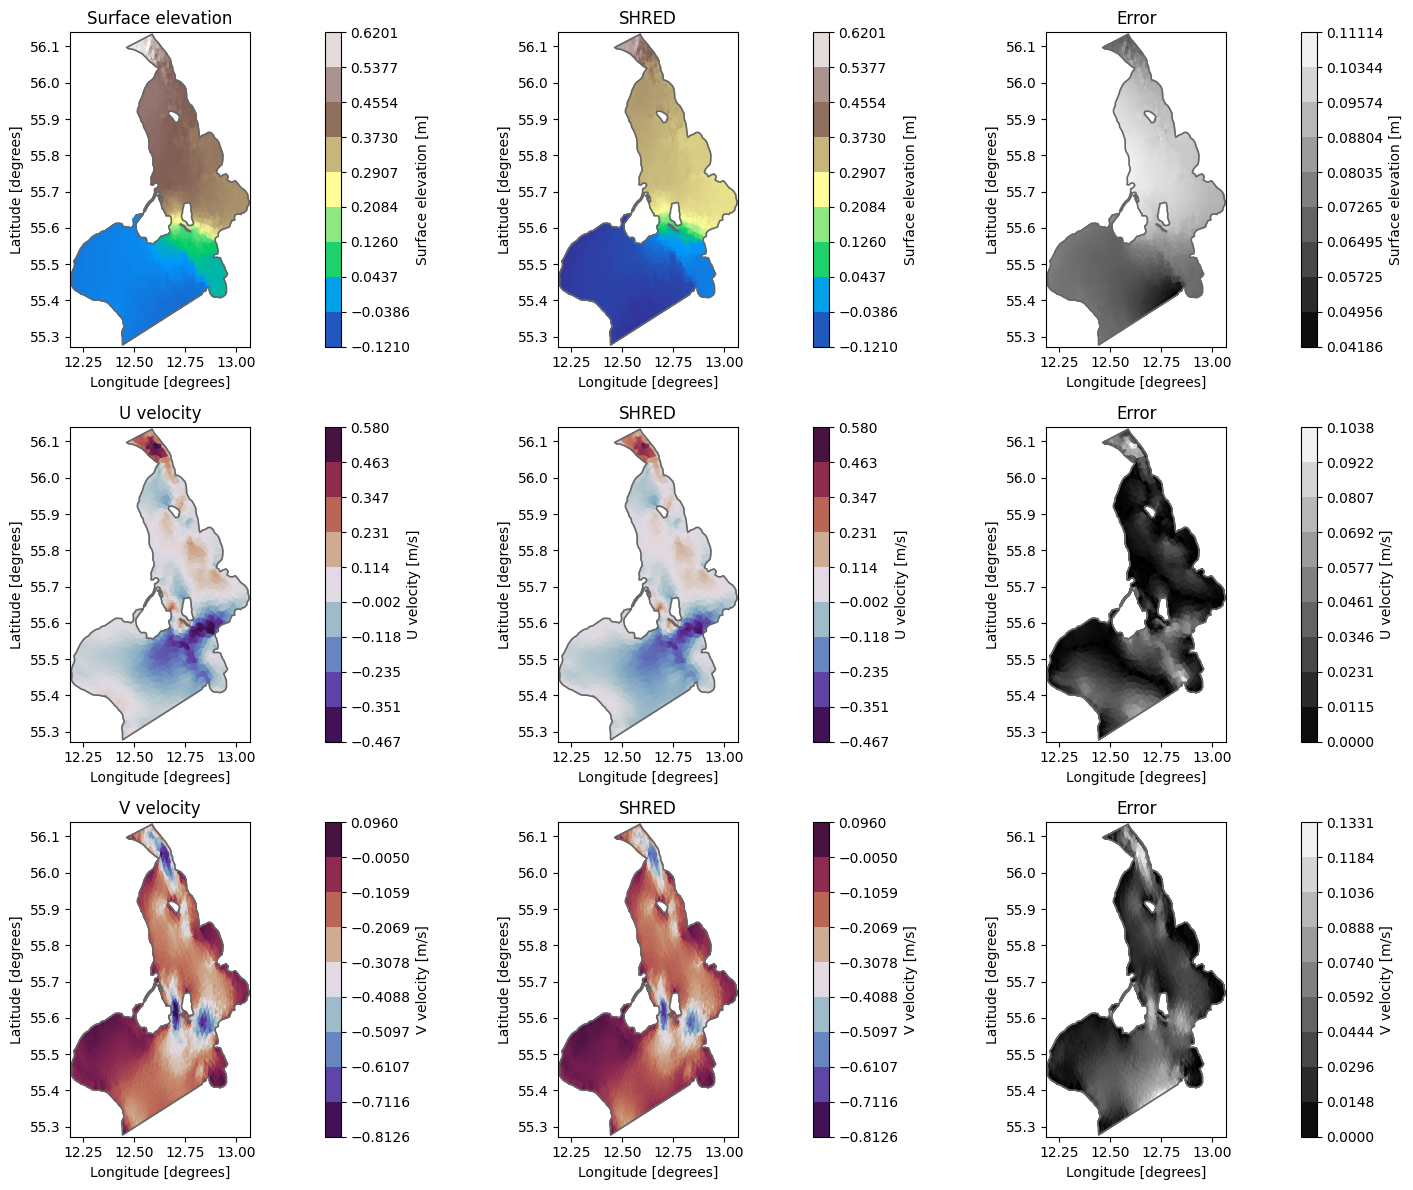

In [13]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.C)_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.2.A) GRUD

In [14]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose=True, masking_type="grud")

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[-1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([59303, 4, 24, 13]) -> torch.Size([59303, 215])
Val:	 torch.Size([12709, 4, 24, 13]) -> torch.Size([12709, 215])
Test:	 torch.Size([12708, 4, 24, 13]) -> torch.Size([12708, 215])

Input shape for the model: 13
Output shape for the model: 215


Starting training...


Training:  69%|██████▉   | 138/200 [31:12<14:01, 13.57s/it, Train Loss=0.00336, Val Loss=0.00376, Patience=39, Best Val Loss=0.00366, LR=1.06e-04]

Early stopping at epoch 139
Training completed with best validation loss: 0.0037


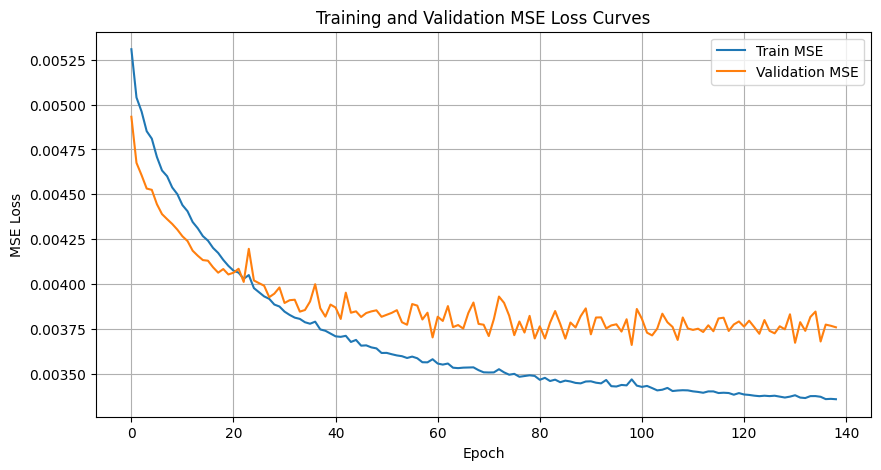

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973


In [15]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): GRUD+{DECODER}", type="(T.2.A): GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.2.A)_GRUD.png


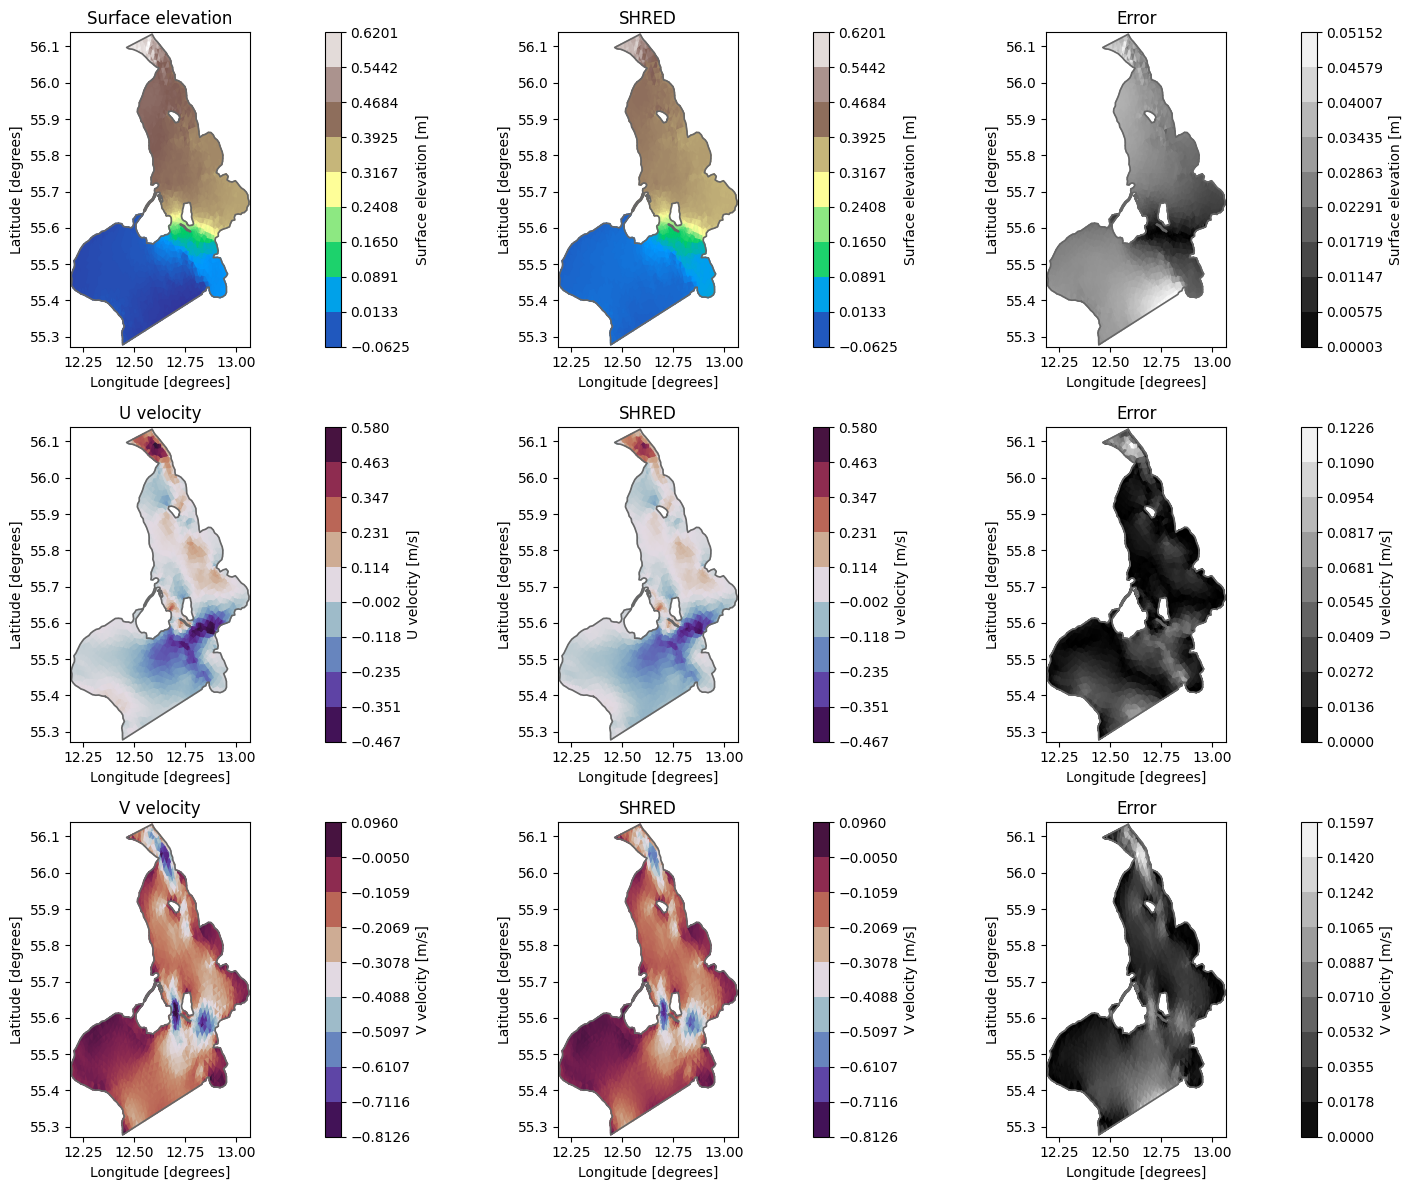

In [16]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.2.A)_GRUD")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, model_args, train_errors, valid_errors, test_error

## (T.2.B): Attn-GRUD

Starting training...


Training:  60%|█████▉    | 119/200 [48:05<32:44, 24.25s/it, Train Loss=0.00349, Val Loss=0.00383, Patience=39, Best Val Loss=0.00369, LR=1.73e-04]

Early stopping at epoch 120
Training completed with best validation loss: 0.0037


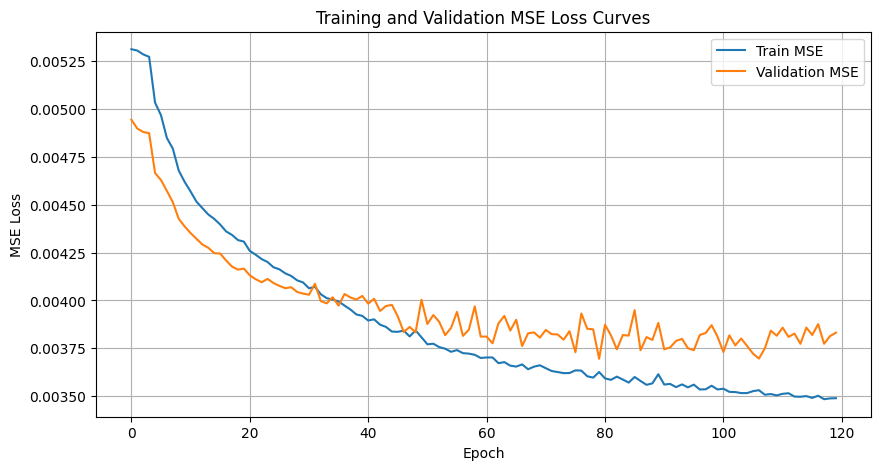

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003626,0.003695,0.004054,0.134603,0.136693,0.139369


In [17]:
# Attn-GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): Attn-GRUD+{DECODER}", type="(T.2.B): Attn-GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.2.B)_Attn-GRUD.png


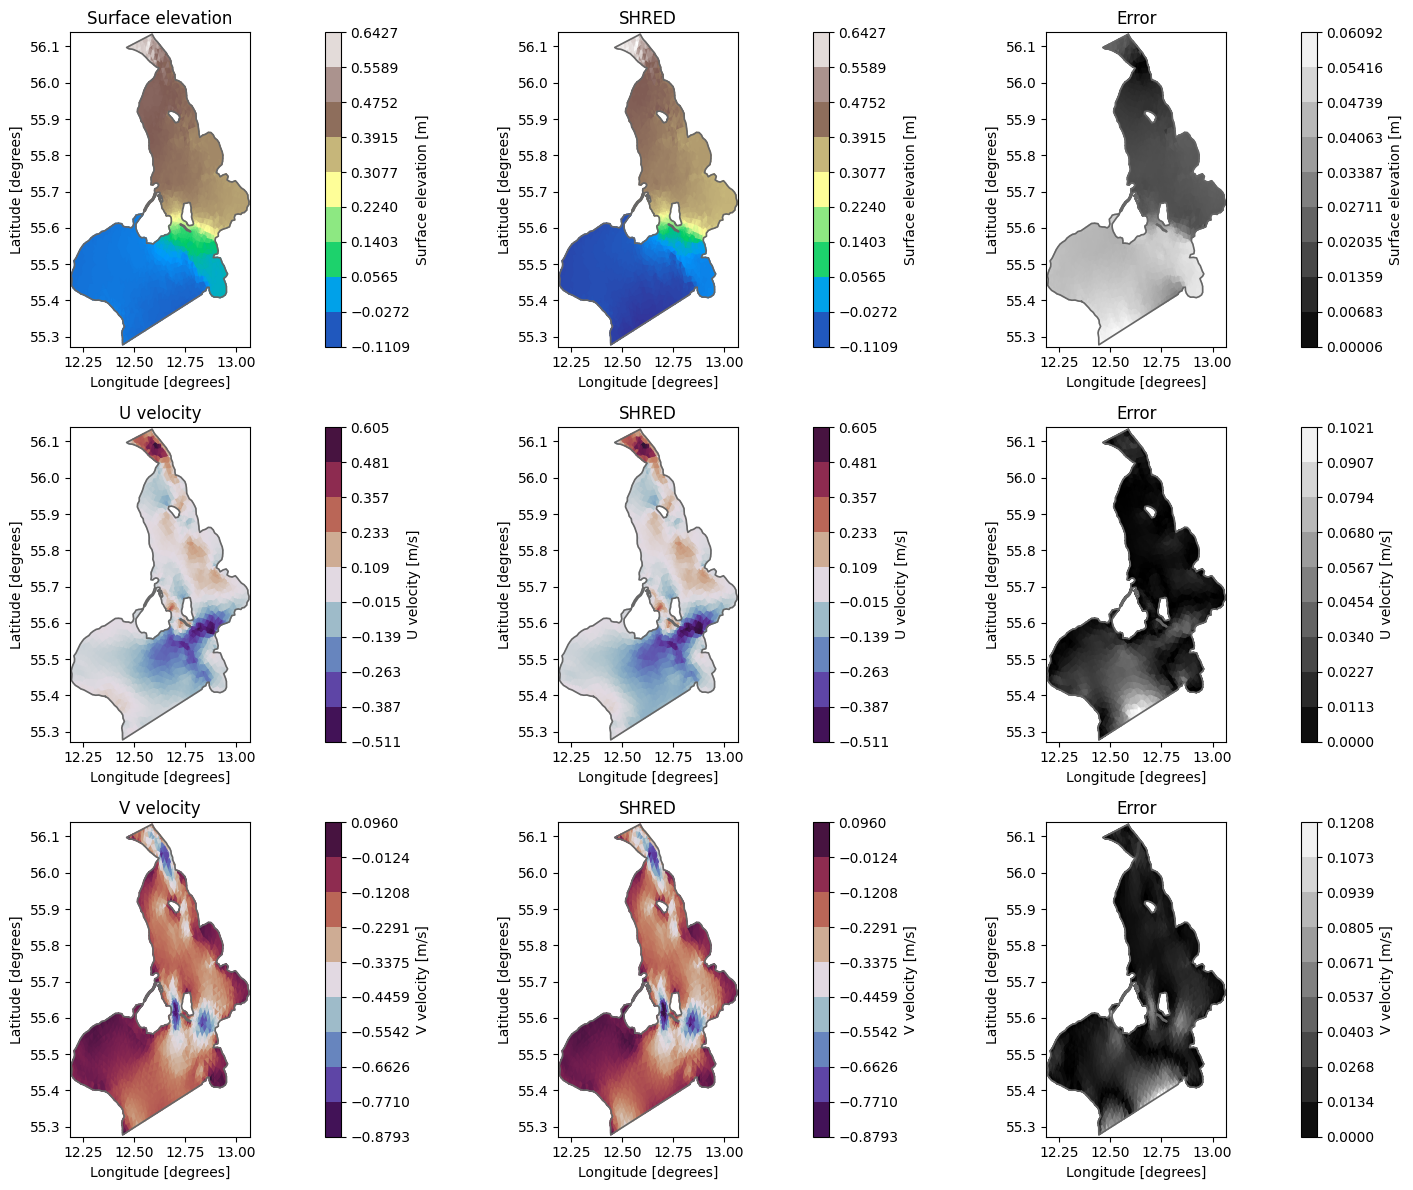

In [18]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.2.B)_Attn-GRUD")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape, X_mean

## (T.3.A): Masking

In [19]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 380967

Data shapes after preparation:
Train:	 torch.Size([59303, 24, 13]) -> torch.Size([59303, 215])
Val:	 torch.Size([12709, 24, 13]) -> torch.Size([12709, 215])
Test:	 torch.Size([12708, 24, 13]) -> torch.Size([12708, 215])

Input shape for the model: 13
Output shape for the model: 215


Starting training...


Training:  70%|███████   | 141/200 [38:57<16:17, 16.58s/it, Train Loss=0.00338, Val Loss=0.00380, Patience=39, Best Val Loss=0.00372, LR=9.68e-05]

Early stopping at epoch 142
Training completed with best validation loss: 0.0037


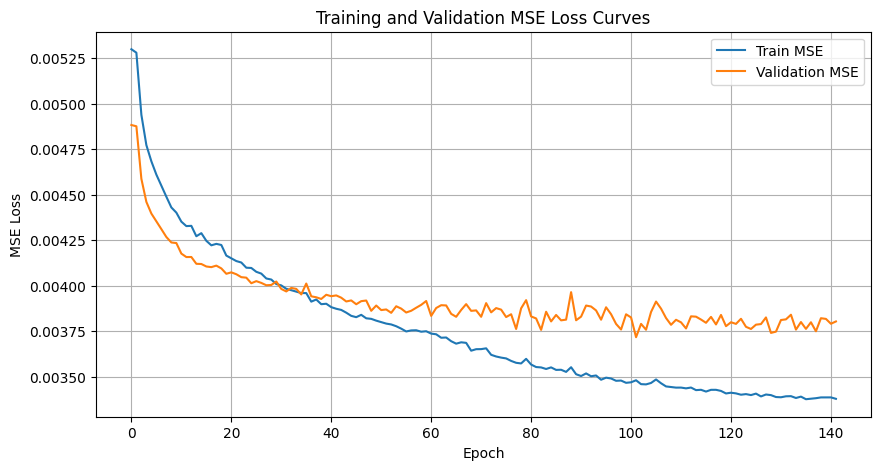

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003626,0.003695,0.004054,0.134603,0.136693,0.139369
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003480,0.003717,0.003978,0.131884,0.136682,0.138503


In [20]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.A): masking", masking_type=MASKING_TYPE
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.A)_masking.png


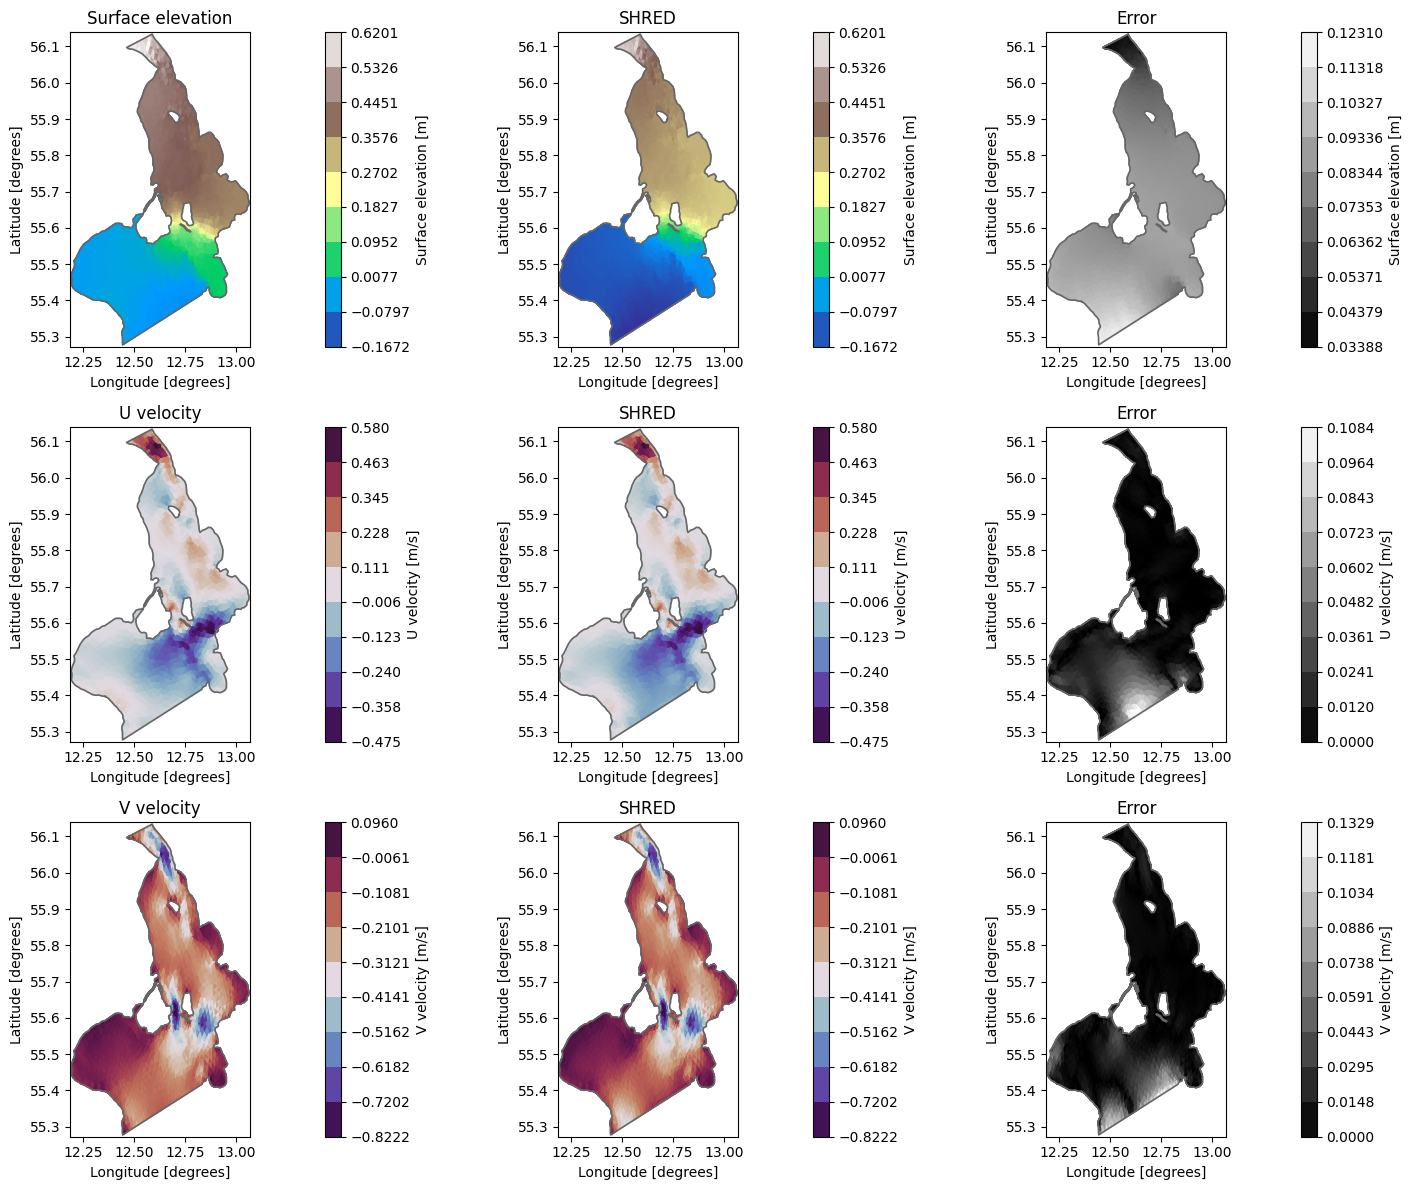

In [21]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.A)_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.B): Masking x2 channels

Starting training...


Training:  76%|███████▌  | 152/200 [42:08<13:18, 16.63s/it, Train Loss=0.00326, Val Loss=0.00376, Patience=39, Best Val Loss=0.00366, LR=6.51e-05]

Early stopping at epoch 153
Training completed with best validation loss: 0.0037


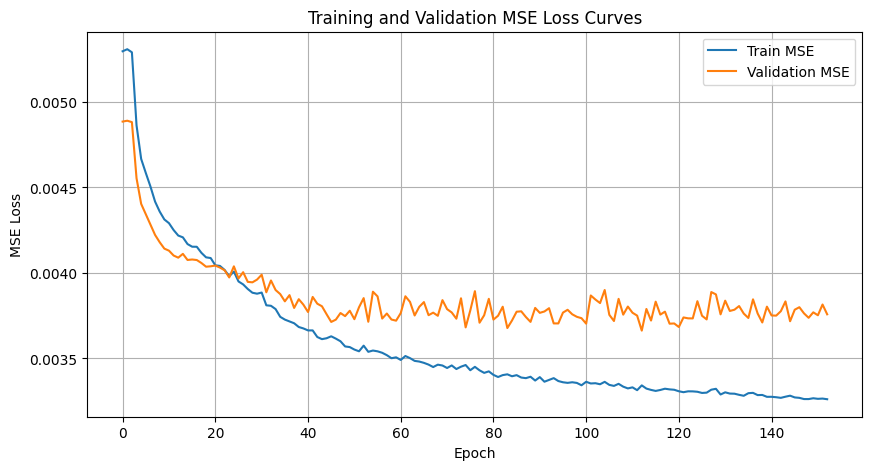

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003626,0.003695,0.004054,0.134603,0.136693,0.139369
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003480,0.003717,0.003978,0.131884,0.136682,0.138503
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003343,0.003663,0.003980,0.129477,0.135770,0.138434


In [22]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.B): masking x2 channels", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.B)_masking_x2_channels.png


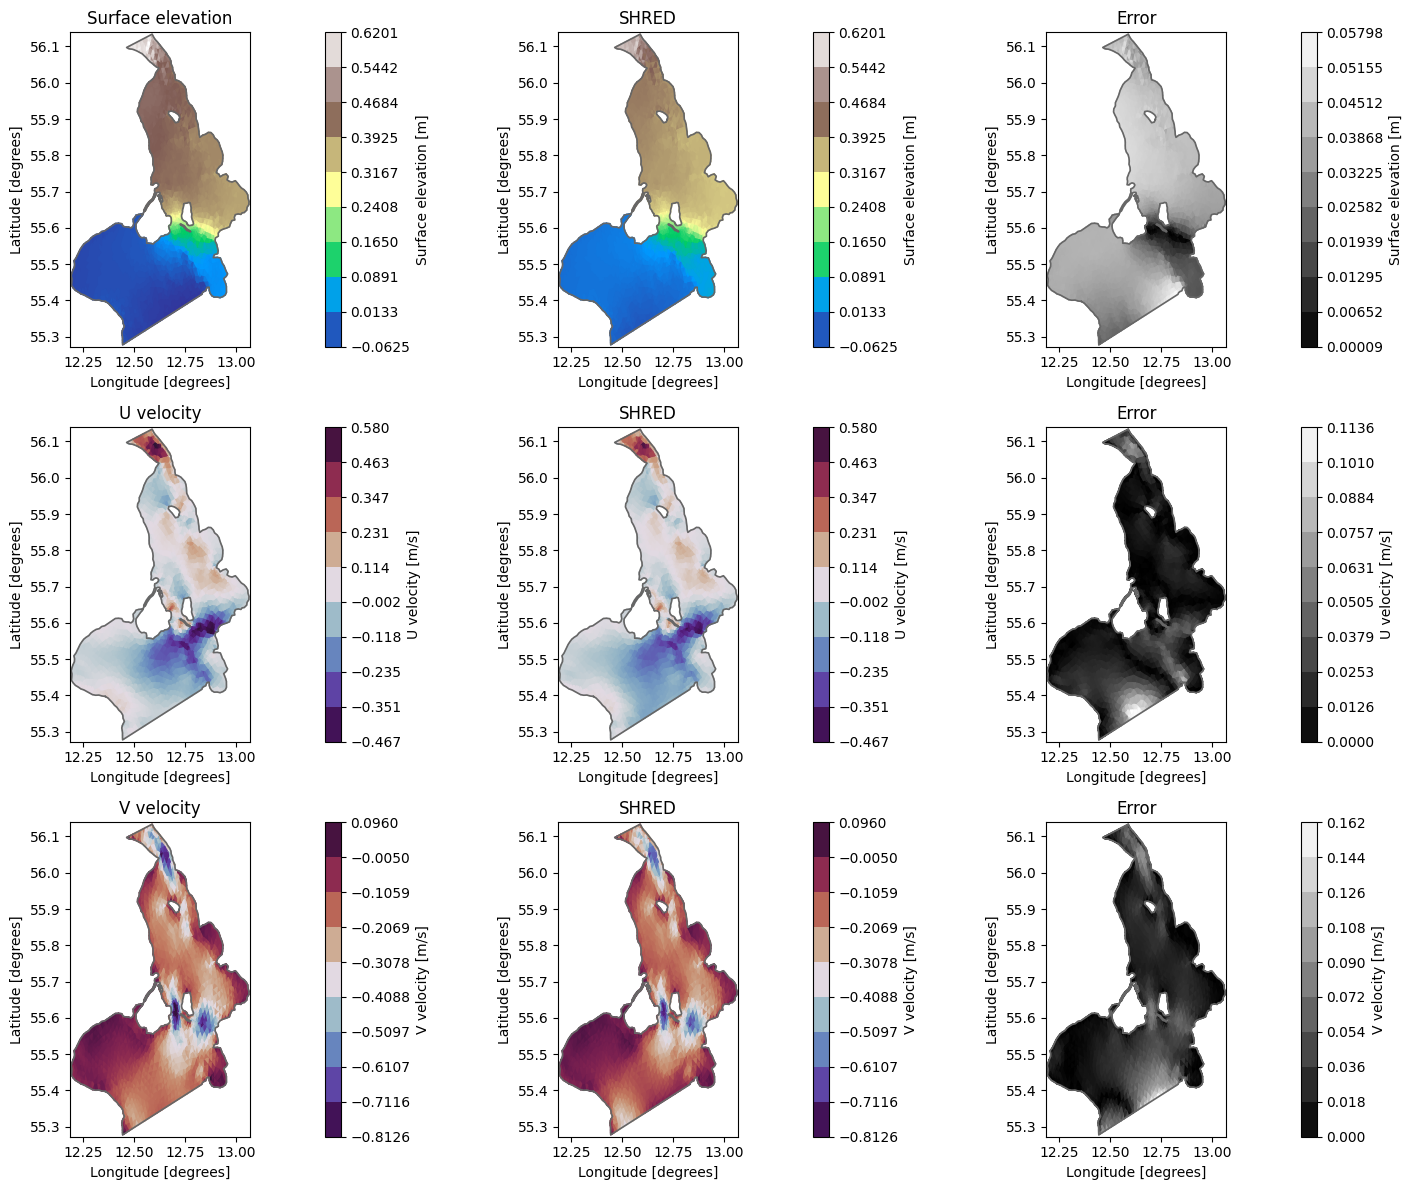

In [23]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.B)_masking_x2_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.C): Masking hidden space

Starting training...


Training:  54%|█████▍    | 108/200 [30:02<25:35, 16.69s/it, Train Loss=0.00337, Val Loss=0.00388, Patience=39, Best Val Loss=0.00371, LR=2.15e-04]

Early stopping at epoch 109
Training completed with best validation loss: 0.0037


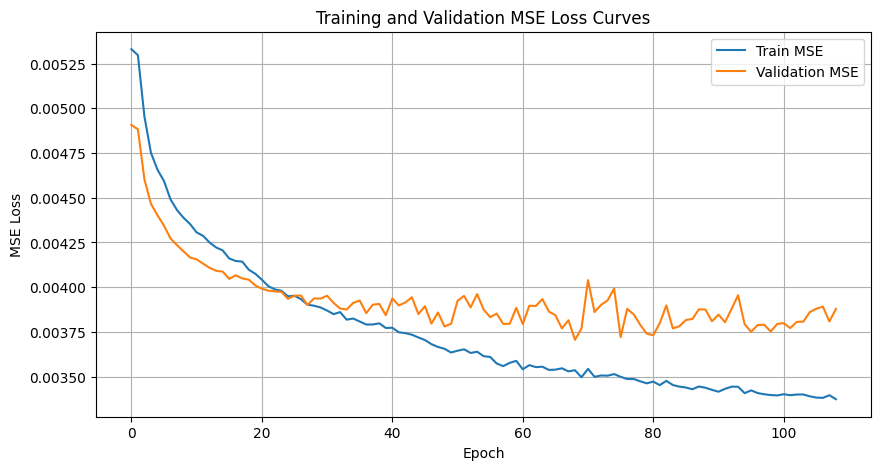

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003626,0.003695,0.004054,0.134603,0.136693,0.139369
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003480,0.003717,0.003978,0.131884,0.136682,0.138503
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003343,0.003663,0.003980,0.129477,0.135770,0.138434
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003536,0.003706,0.004026,0.132807,0.136626,0.138918


In [24]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.C): masking hidden space", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.C)_masking_hidden_space.png


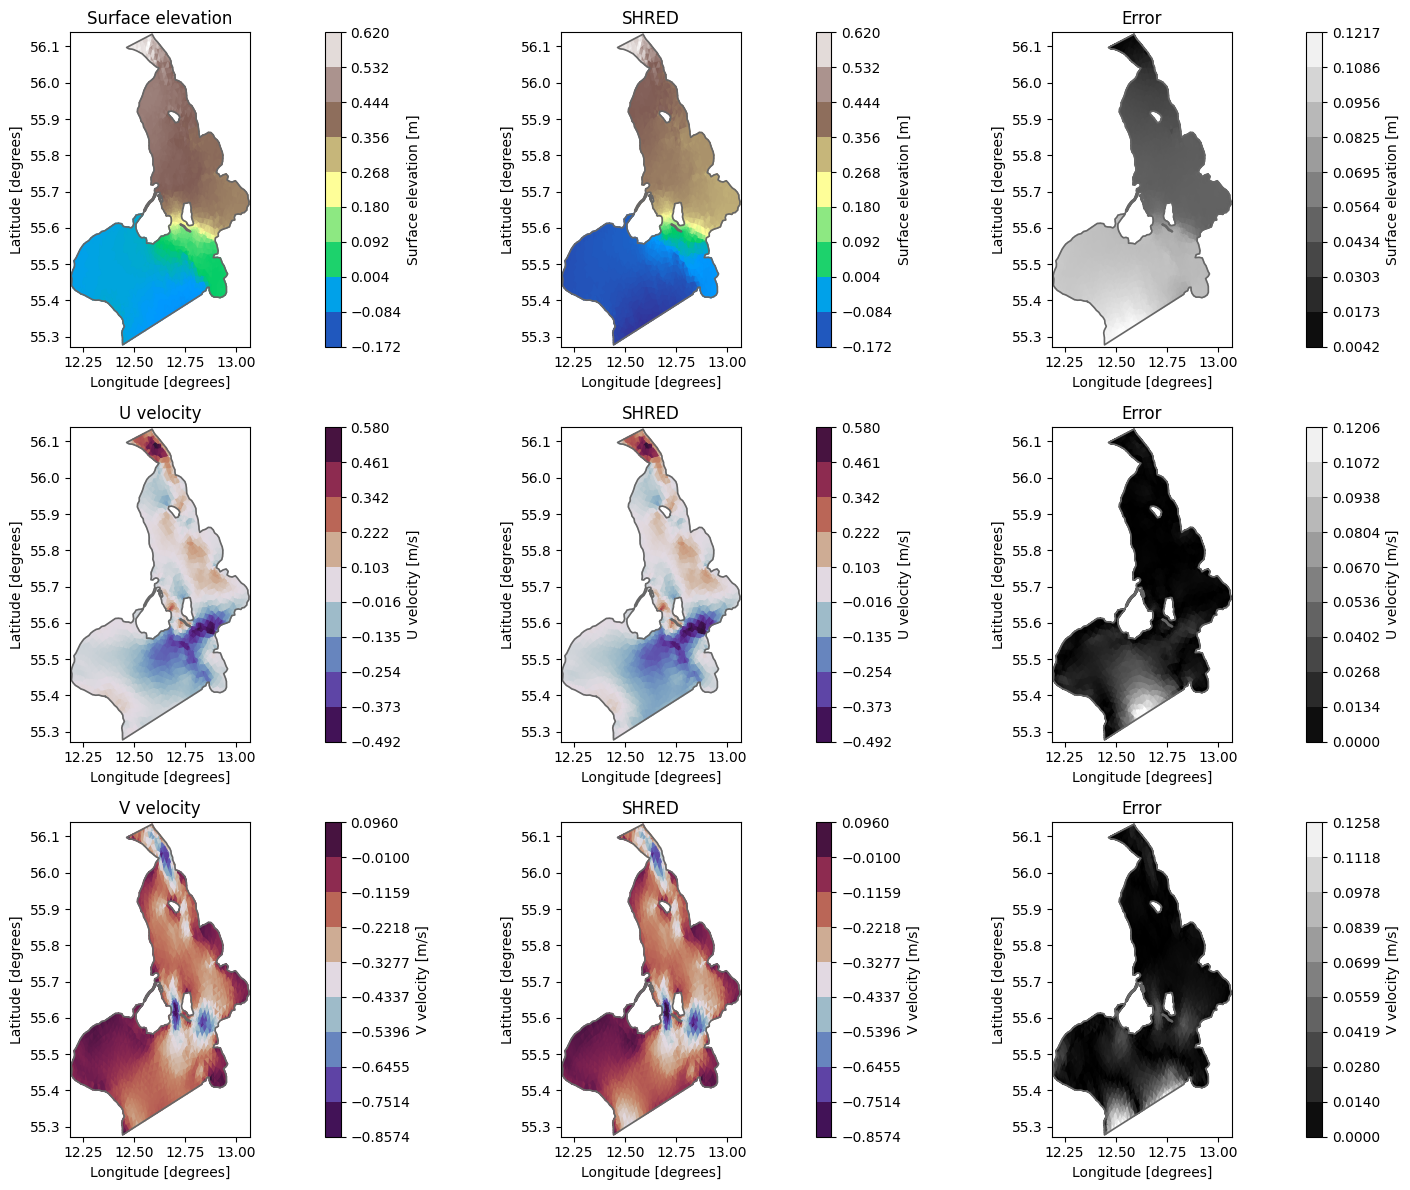

In [25]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.C)_masking_hidden_space")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.D): Masking MHSA

Starting training...


Training:  52%|█████▏    | 104/200 [29:29<27:13, 17.02s/it, Train Loss=0.00340, Val Loss=0.00384, Patience=39, Best Val Loss=0.00378, LR=2.30e-04]

Early stopping at epoch 105
Training completed with best validation loss: 0.0038


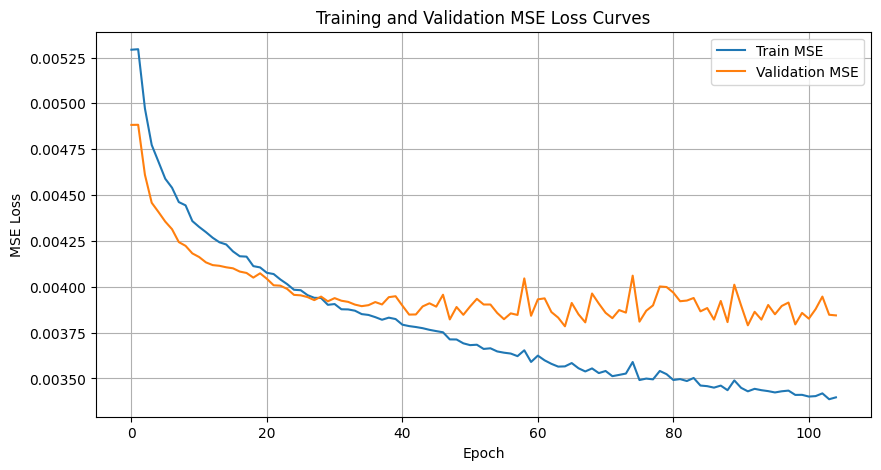

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003626,0.003695,0.004054,0.134603,0.136693,0.139369
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003480,0.003717,0.003978,0.131884,0.136682,0.138503
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003343,0.003663,0.003980,0.129477,0.135770,0.138434
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003536,0.003706,0.004026,0.132807,0.136626,0.138918
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003566,0.003784,0.004076,0.133433,0.137855,0.139557


In [26]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.D): masking MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.D)_masking_MHSA.png


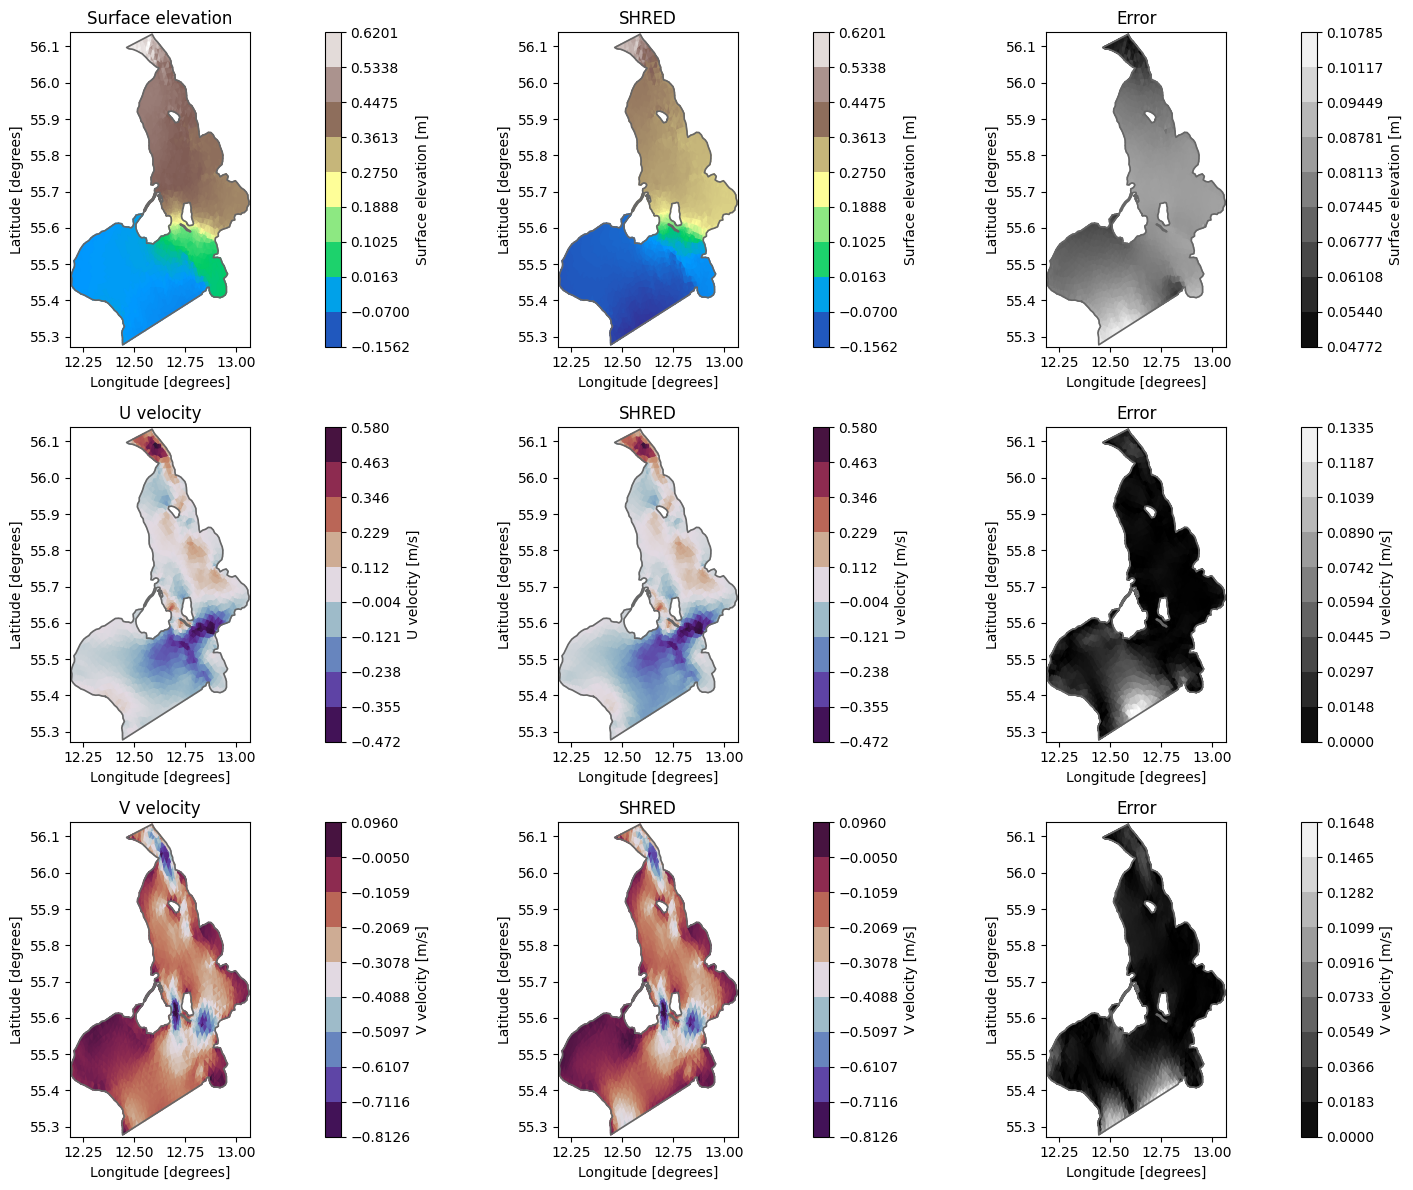

In [27]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.D)_masking_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.E): Masking x2 channels + MHSA

Starting training...


Training:  73%|███████▎  | 146/200 [41:24<15:19, 17.02s/it, Train Loss=0.00332, Val Loss=0.00372, Patience=39, Best Val Loss=0.00368, LR=8.17e-05]

Early stopping at epoch 147
Training completed with best validation loss: 0.0037


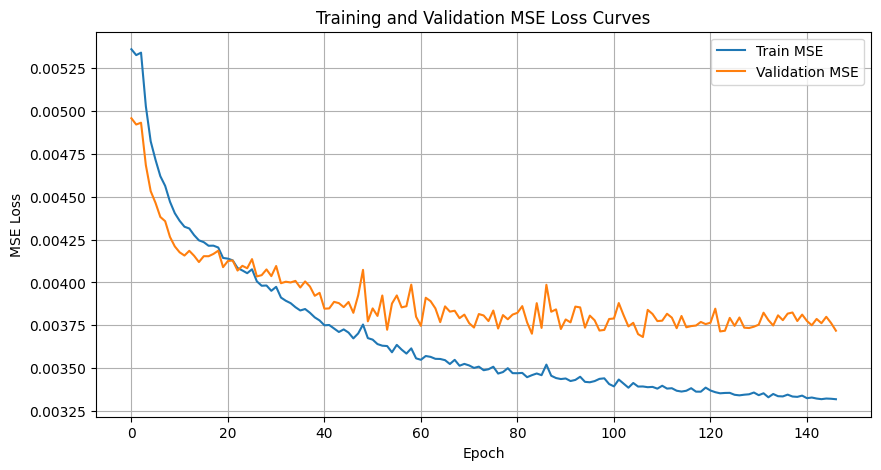

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003626,0.003695,0.004054,0.134603,0.136693,0.139369
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003480,0.003717,0.003978,0.131884,0.136682,0.138503
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003343,0.003663,0.003980,0.129477,0.135770,0.138434
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003536,0.003706,0.004026,0.132807,0.136626,0.138918
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003566,0.003784,0.004076,0.133433,0.137855,0.139557
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003394,0.003682,0.003988,0.130391,0.136204,0.138582


In [28]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.E): masking x2 channels + MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.E)_masking_x2_channels_MHSA.png


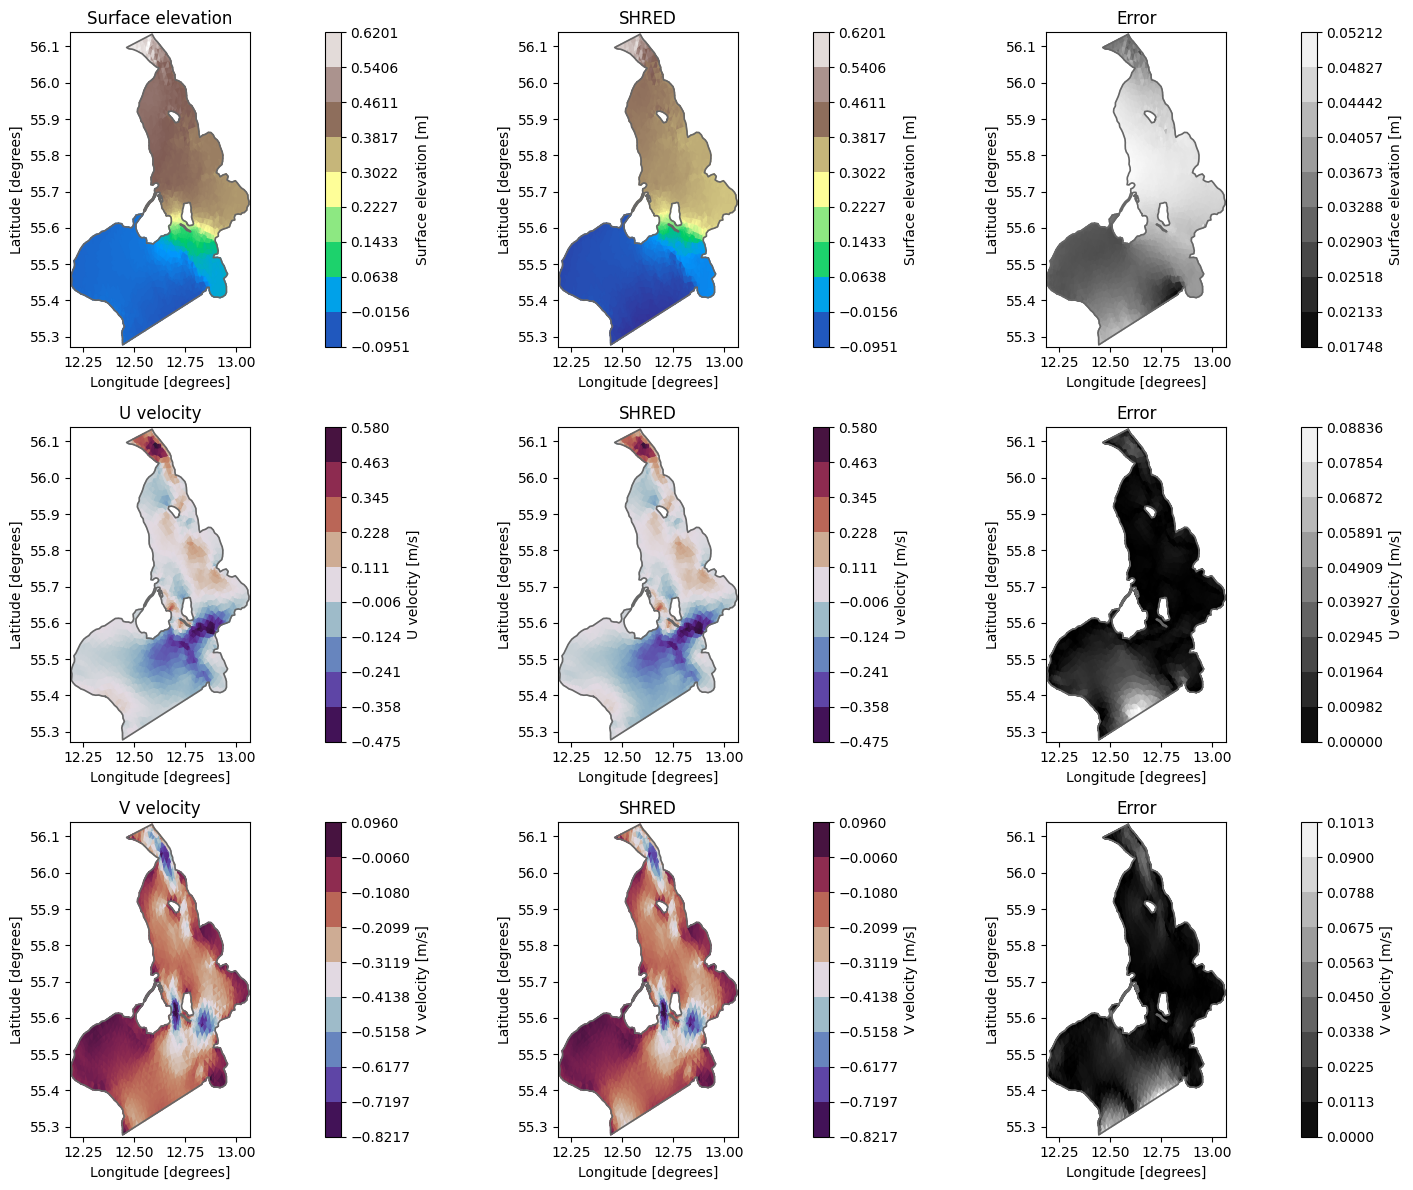

In [29]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.E)_masking_x2_channels_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.F): Masking MHSA learned

Starting training...


Training:  92%|█████████▏| 183/200 [1:01:18<05:41, 20.10s/it, Train Loss=0.00330, Val Loss=0.00366, Patience=39, Best Val Loss=0.00363, LR=7.85e-06]

Early stopping at epoch 184
Training completed with best validation loss: 0.0036


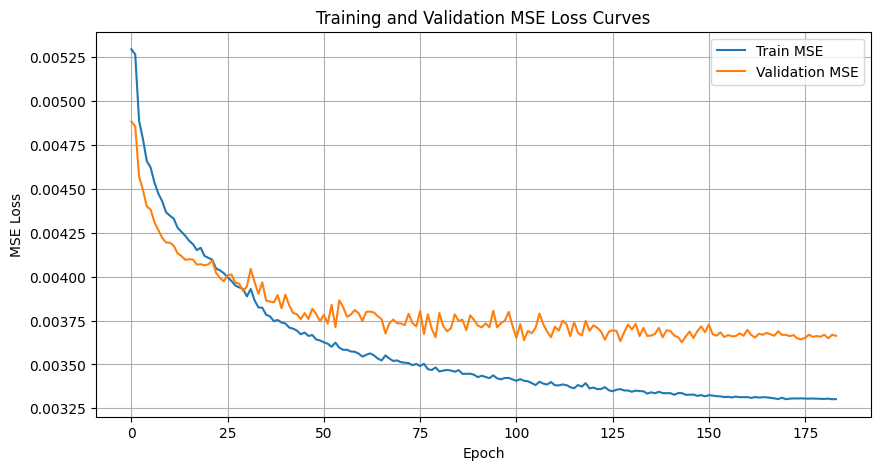

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003626,0.003695,0.004054,0.134603,0.136693,0.139369
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003480,0.003717,0.003978,0.131884,0.136682,0.138503
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003343,0.003663,0.003980,0.129477,0.135770,0.138434
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003536,0.003706,0.004026,0.132807,0.136626,0.138918
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003566,0.003784,0.004076,0.133433,0.137855,0.139557
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003394,0.003682,0.003988,0.130391,0.136204,0.138582


In [30]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.F)_masking_MHSA_learned.png


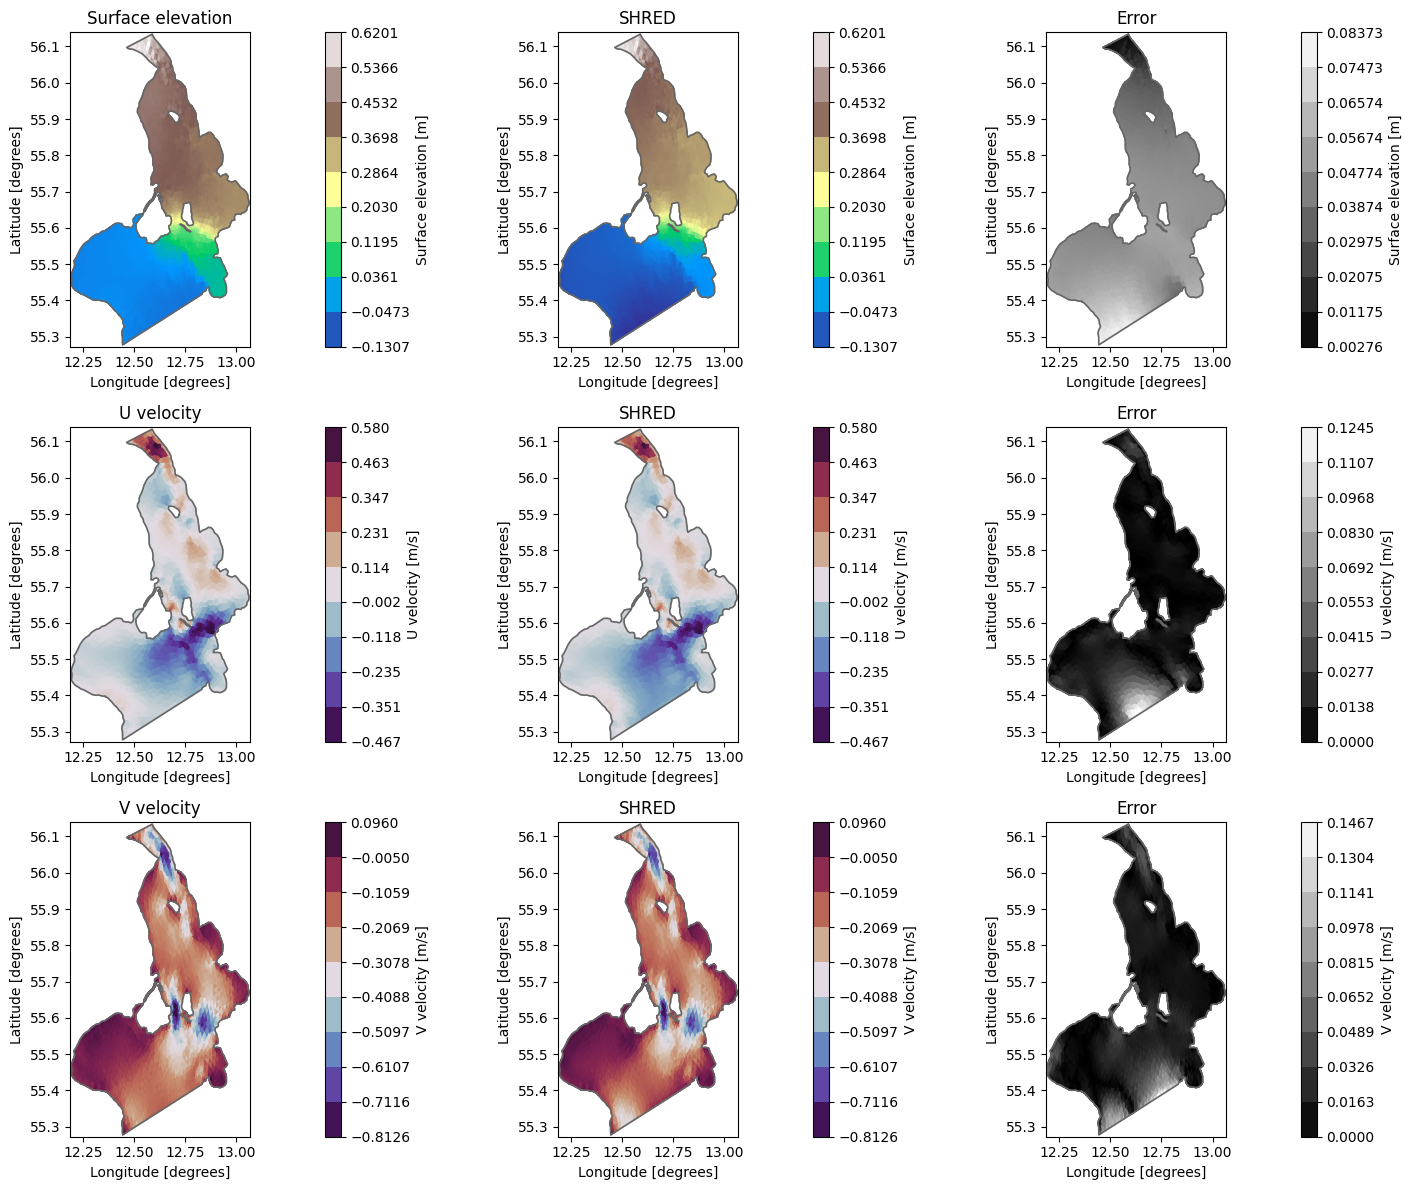

In [31]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.F)_masking_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.G): Masking x2 channels + MHSA learned

Starting training...


Training:  86%|████████▌ | 171/200 [57:53<09:49, 20.31s/it, Train Loss=0.00334, Val Loss=0.00375, Patience=39, Best Val Loss=0.00369, LR=2.38e-05]

Early stopping at epoch 172
Training completed with best validation loss: 0.0037


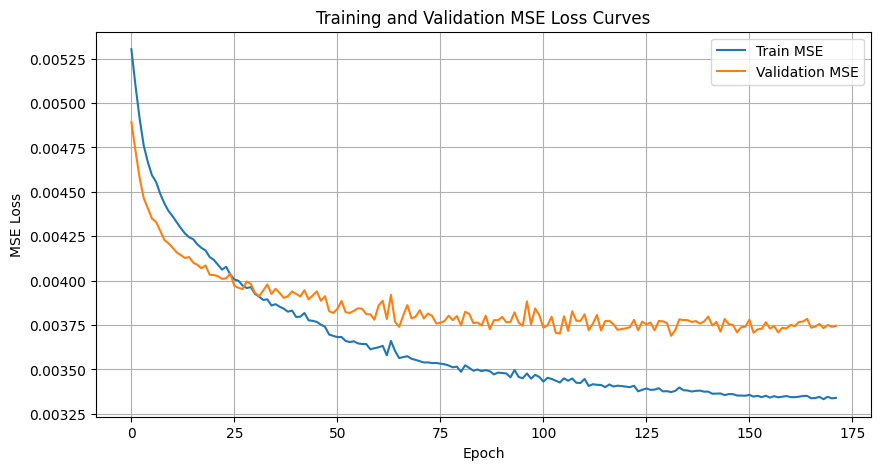

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003574,0.003740,0.004024,0.133716,0.137047,0.138871
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003428,0.003727,0.004028,0.131093,0.136988,0.138968
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003342,0.003693,0.004036,0.129666,0.136667,0.139002
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003468,0.003660,0.004235,0.131807,0.136040,0.140973
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003626,0.003695,0.004054,0.134603,0.136693,0.139369
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003480,0.003717,0.003978,0.131884,0.136682,0.138503
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003343,0.003663,0.003980,0.129477,0.135770,0.138434
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003536,0.003706,0.004026,0.132807,0.136626,0.138918
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003566,0.003784,0.004076,0.133433,0.137855,0.139557
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003394,0.003682,0.003988,0.130391,0.136204,0.138582


In [32]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.G)_masking_x2_channels_MHSA_learned.png


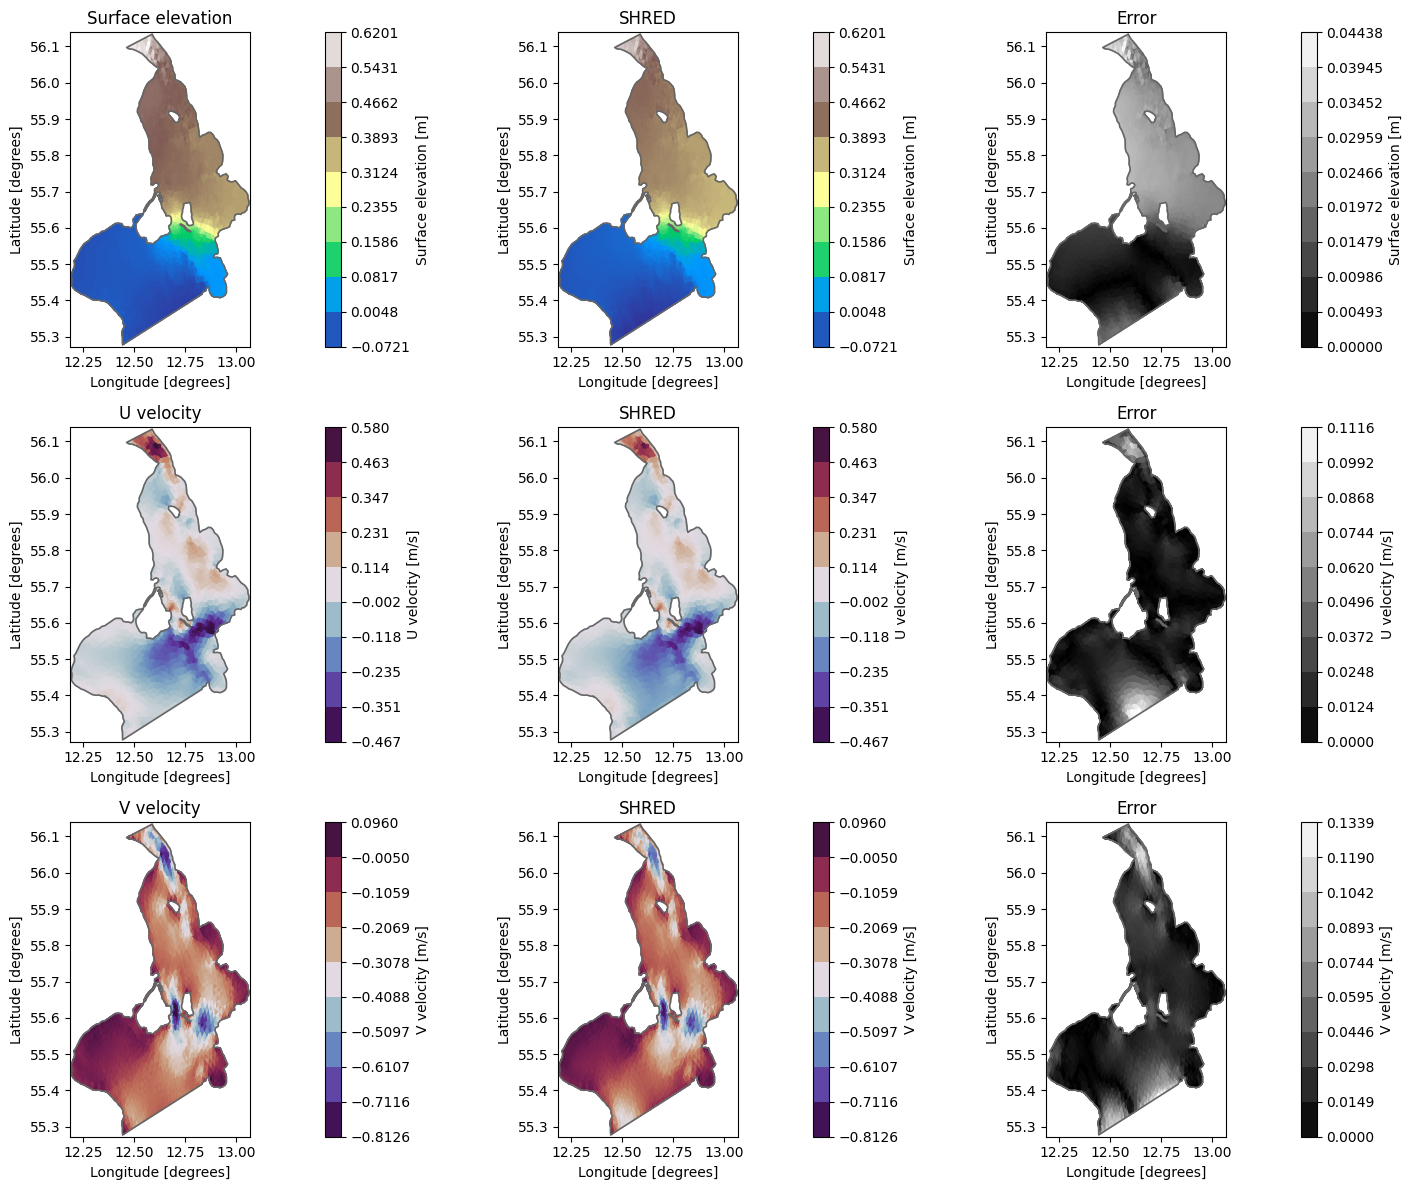

In [33]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.G)_masking_x2_channels_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## Results

In [4]:
dataframe_errors = pd.read_csv("results_df/Notebook1/dataframe_errors.csv")
display(dataframe_errors)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003666,0.003735,0.004023,0.138915,0.140910,0.142842
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003598,0.003638,0.004006,0.137500,0.138847,0.141935
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003134,0.003591,0.004034,0.128700,0.138057,0.141743
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003401,0.003669,0.005014,0.133743,0.140091,0.151024
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003452,0.003716,0.004437,0.134689,0.140960,0.148966
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003482,0.003729,0.003814,0.135789,0.141084,0.140481
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003281,0.003584,0.003821,0.131727,0.138601,0.140180
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003311,0.003518,0.003676,0.132189,0.137214,0.137725
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003150,0.003770,0.003867,0.128886,0.141945,0.141443
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003233,0.003570,0.003776,0.130841,0.138061,0.139124


Saved PDF and PNG.


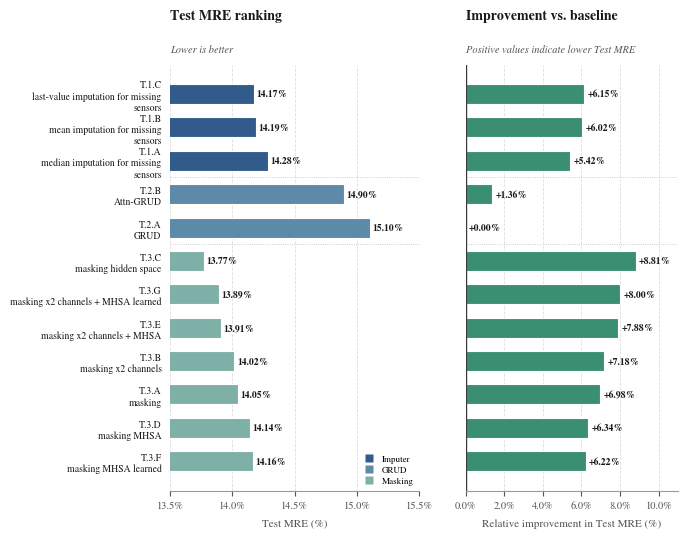

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap
from matplotlib.ticker import FuncFormatter

# ============================================================
# PAPER-READY SETTINGS
# ============================================================
# - Vector-safe fonts (Type 42) so PDF/EPS embed correctly in LaTeX
# - Serif font to match most journal body text (swap to sans if your
#   venue uses a sans-serif font, e.g. "DejaVu Sans" / "Arial")
# - White background (no off-white/slide-deck backdrop)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "axes.unicode_minus": False,
})

# Set BASELINE_PATTERN to the substring identifying your baseline row
# (e.g. "T.0"). If no row matches, the code falls back to using the
# worst-performing (highest test-mre) row as the reference point.
BASELINE_PATTERN = "T.0"

# ============================================================
# LOAD DATA
# ============================================================

dataframe_errors = pd.read_csv("results_df/Notebook1/dataframe_errors.csv")

df_plot = dataframe_errors.copy()

# ------------------------------------------------------------
# Parse "(TAG): description" -> separate columns, and pull the
# ablation-group number out of the tag (T.1 / T.2 / T.3 / ...).
# Grouping keeps a long ablation table legible: rows are blocked
# by experiment family instead of one flat 13-row ranking.
# ------------------------------------------------------------
extracted = df_plot["type"].str.extract(r"^\(([^)]+)\):\s*(.*)$")
df_plot["tag"] = extracted[0].fillna(df_plot["type"])
df_plot["desc"] = extracted[1].fillna("")

df_plot["group"] = df_plot["tag"].str.extract(r"^T\.(\d+)").fillna("0")
group_order = sorted(df_plot["group"].unique(), key=lambda g: int(g))

df_plot = (
    df_plot
    .sort_values(["group", "test-mre"])
    .reset_index(drop=True)
)

baseline_mask = df_plot["type"].str.contains(BASELINE_PATTERN, regex=False)

if baseline_mask.any():
    baseline_idx = df_plot.index[baseline_mask][0]
    baseline_test_mre = df_plot.loc[baseline_idx, "test-mre"]
else:
    baseline_idx = None
    baseline_test_mre = df_plot["test-mre"].max()

# Convert to percentage
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_baseline_%"] = (
    100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre
)

# Wrap the description only (tag is shown separately via color), which
# keeps rows compact when there are many of them
df_plot["desc_wrapped"] = [
    "\n".join(textwrap.wrap(str(s), width=34))
    for s in df_plot["desc"]
]
df_plot["type_wrapped"] = df_plot["tag"] + "\n" + df_plot["desc_wrapped"]

n_models = len(df_plot)
y = np.arange(n_models)

# ============================================================
# STYLE — print-safe palette (also fine in grayscale)
# ============================================================

BLUE = "#315B8A"
GREEN = "#3A8F72"
RED = "#C65A54"
GOLD = "#D39B32"

TEXT = "#1A1A1A"
SECONDARY = "#555555"
GRID = "#DADADA"

# One color per ablation group (T.1 / T.2 / T.3 / ...), reused across
# both panels' left-side tick coloring so the reader can track a family
# of experiments down the whole table.
# Map each group number to a human-readable name for the legend; any
# group not listed here falls back to "Group N".
GROUP_NAMES = {
    "1": "Imputer",
    "2": "GRUD",
    "3": "Masking",
}
GROUP_PALETTE = ["#315B8A", "#5C8AA8", "#7FB0A8", "#A8A040", "#8A5C9E"]
group_colors = {
    g: GROUP_PALETTE[i % len(GROUP_PALETTE)]
    for i, g in enumerate(group_order)
}
group_labels = {
    g: GROUP_NAMES.get(g, f"Group {g}")
    for g in group_order
}

# ============================================================
# FIGURE — sized for a double-column journal figure
# (7.16 in is the standard IEEE/Elsevier two-column text width;
#  use 3.5 in single-column if you stack panels vertically instead)
# ============================================================

FIG_WIDTH_IN = 7.16
fig_height = max(2.6, 0.34 * n_models + 1.6)

fig, axes = plt.subplots(
    1, 2,
    figsize=(FIG_WIDTH_IN, fig_height),
    gridspec_kw={"width_ratios": [1.08, 0.92], "wspace": 0.20},
)
fig.patch.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("white")


def add_panel_title(ax, title, subtitle):
    ax.text(0.0, 1.10, title, transform=ax.transAxes, fontsize=10,
             fontweight="bold", color=TEXT, ha="left", va="bottom")
    ax.text(0.0, 1.025, subtitle, transform=ax.transAxes, fontsize=7.5,
             color=SECONDARY, ha="left", va="bottom", style="italic")


# ============================================================
# LEFT PANEL — TEST MRE RANKING
# ============================================================

ax = axes[0]
bar_colors_left = [group_colors[g] for g in df_plot["group"]]
bars = ax.barh(y, df_plot["test-mre_%"], height=0.6, color=bar_colors_left,
                edgecolor="white", linewidth=0.8)

if baseline_idx is not None:
    bars[baseline_idx].set_color(GOLD)

ax.set_yticks(y)
ax.set_yticklabels(df_plot["type_wrapped"], fontsize=7, color=TEXT)
ax.invert_yaxis()

# Thin separators between ablation groups
group_boundaries = np.where(df_plot["group"].values[:-1] != df_plot["group"].values[1:])[0]
for b in group_boundaries:
    ax.axhline(b + 0.5, color="#BFBFBF", linewidth=0.6, linestyle=":", zorder=1)

add_panel_title(ax, "Test MRE ranking", "Lower is better")
ax.set_xlabel("Test MRE (%)", fontsize=8, color=SECONDARY, labelpad=6)

# Auto-range with a small margin instead of a hardcoded 12-15 window,
# so the script generalizes to other data
lo = np.floor(df_plot["test-mre_%"].min() * 4) / 4 - 0.25
hi = np.ceil(df_plot["test-mre_%"].max() * 4) / 4 + 0.25
ax.set_xlim(lo, hi)

ax.grid(axis="x", linestyle="--", linewidth=0.6, color=GRID, alpha=0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

for i, value in enumerate(df_plot["test-mre_%"]):
    ax.text(min(value + 0.02, hi - 0.04), i, f"{value:.2f}%", va="center",
             ha="left", fontsize=7, fontweight="bold", color=TEXT)

# Legend mapping group color -> group tag prefix (e.g. "T.1", "T.2")
legend_handles = [
    plt.Line2D([0], [0], marker="s", linestyle="none", markersize=6,
               markerfacecolor=group_colors[g], markeredgecolor="none",
               label=group_labels[g])
    for g in group_order
]
ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=6.5,
    frameon=False,
    handletextpad=0.4,
    labelspacing=0.3,
    borderaxespad=0.2,
)

# ============================================================
# RIGHT PANEL — IMPROVEMENT VS BASELINE
# ============================================================

ax = axes[1]
improvement = df_plot["improvement_vs_baseline_%"]

bar_colors = [
    GREEN if v > 1e-4 else RED if v < -1e-4 else "#8A8A8A"
    for v in improvement
]

ax.barh(y, improvement, height=0.6, color=bar_colors,
        edgecolor="white", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels([])
ax.invert_yaxis()
ax.axvline(0, color="#3A3A3A", linewidth=1.0, zorder=3)

for b in group_boundaries:
    ax.axhline(b + 0.5, color="#BFBFBF", linewidth=0.6, linestyle=":", zorder=1)

baseline_label = (
    df_plot.loc[baseline_idx, "type"] if baseline_idx is not None
    else "worst configuration"
)
add_panel_title(ax, "Improvement vs. baseline",
                 "Positive values indicate lower Test MRE")
ax.set_xlabel("Relative improvement in Test MRE (%)", fontsize=8,
              color=SECONDARY, labelpad=6)

ax.grid(axis="x", linestyle="--", linewidth=0.6, color=GRID, alpha=0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

max_positive = max(improvement.max(), 0.5)
max_negative = min(improvement.min(), 0)
ax.set_xlim(max_negative * 1.25, max_positive * 1.25)

max_abs = max(abs(improvement.min()), abs(improvement.max()), 0.5)
for i, value in enumerate(improvement):
    if value >= 0:
        ax.text(value + 0.02 * max_abs, i, f"+{value:.2f}%", va="center",
                 ha="left", fontsize=7, fontweight="bold", color=TEXT)
    else:
        ax.text(value - 0.02 * max_abs, i, f"{value:.2f}%", va="center",
                 ha="right", fontsize=7, fontweight="bold", color=TEXT)

# ============================================================
# AXIS CLEANUP
# ============================================================

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#999999")
    ax.tick_params(axis="y", length=0, pad=6)
    ax.tick_params(axis="x", colors=SECONDARY, labelsize=7.5)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.1f}%"))

if baseline_idx is not None:
    tick = axes[0].get_yticklabels()[baseline_idx]
    tick.set_fontweight("bold")
    tick.set_color("#9A711E")

# No in-image suptitle/caption text: papers caption figures via
# \caption{...} in LaTeX. If you want a caption note in the image
# anyway (e.g. for a slide reuse), uncomment below:
#
# fig.text(0.01, 0.01, f"Baseline: {baseline_label}", fontsize=6.5,
#           color=SECONDARY)

fig.subplots_adjust(top=0.88, bottom=0.13, left=0.27, right=0.98, wspace=0.22)

# ============================================================
# SAVE — vector PDF for LaTeX inclusion, PNG for quick preview
# ============================================================

fig.savefig("model_performance_summary.pdf", bbox_inches="tight")
fig.savefig("model_performance_summary.png", dpi=300, bbox_inches="tight")
print("Saved PDF and PNG.")